# Assignment 2 — Fourier Transform

## Setup


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Load the cameraman image. It is already grayscale (uint8, 0-255).
image = data.camera()


## 1.1 — 2D DFT and the frequency spectrum


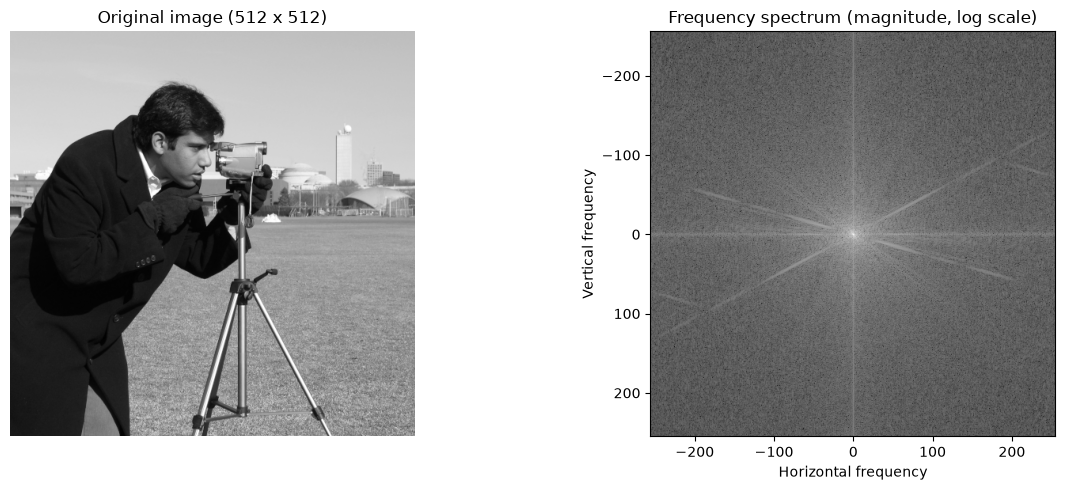

In [13]:
# 2D DFT. fft2 puts the zero frequency in the corners; fftshift moves it to
# the centre. The output is complex, so we visualise its magnitude |F(u, v)|,
# log-scaled because the DC term (the sum of all pixel intensities) otherwise
# dominates the dynamic range.
F = np.fft.fftshift(np.fft.fft2(image.astype(np.float64)))
magnitude_log = np.log(1 + np.abs(F))

H, W = image.shape
u = np.arange(W) - W // 2
v = np.arange(H) - H // 2

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title(f"Original image ({H} x {W})")
axes[0].axis("off")

axes[1].imshow(magnitude_log, cmap="gray", extent=[u[0], u[-1], v[-1], v[0]])
axes[1].set_title("Frequency spectrum (magnitude, log scale)")
axes[1].set_xlabel("Horizontal frequency")
axes[1].set_ylabel("Vertical frequency")

plt.tight_layout()
plt.show()


## 1.2 — Low-pass filter


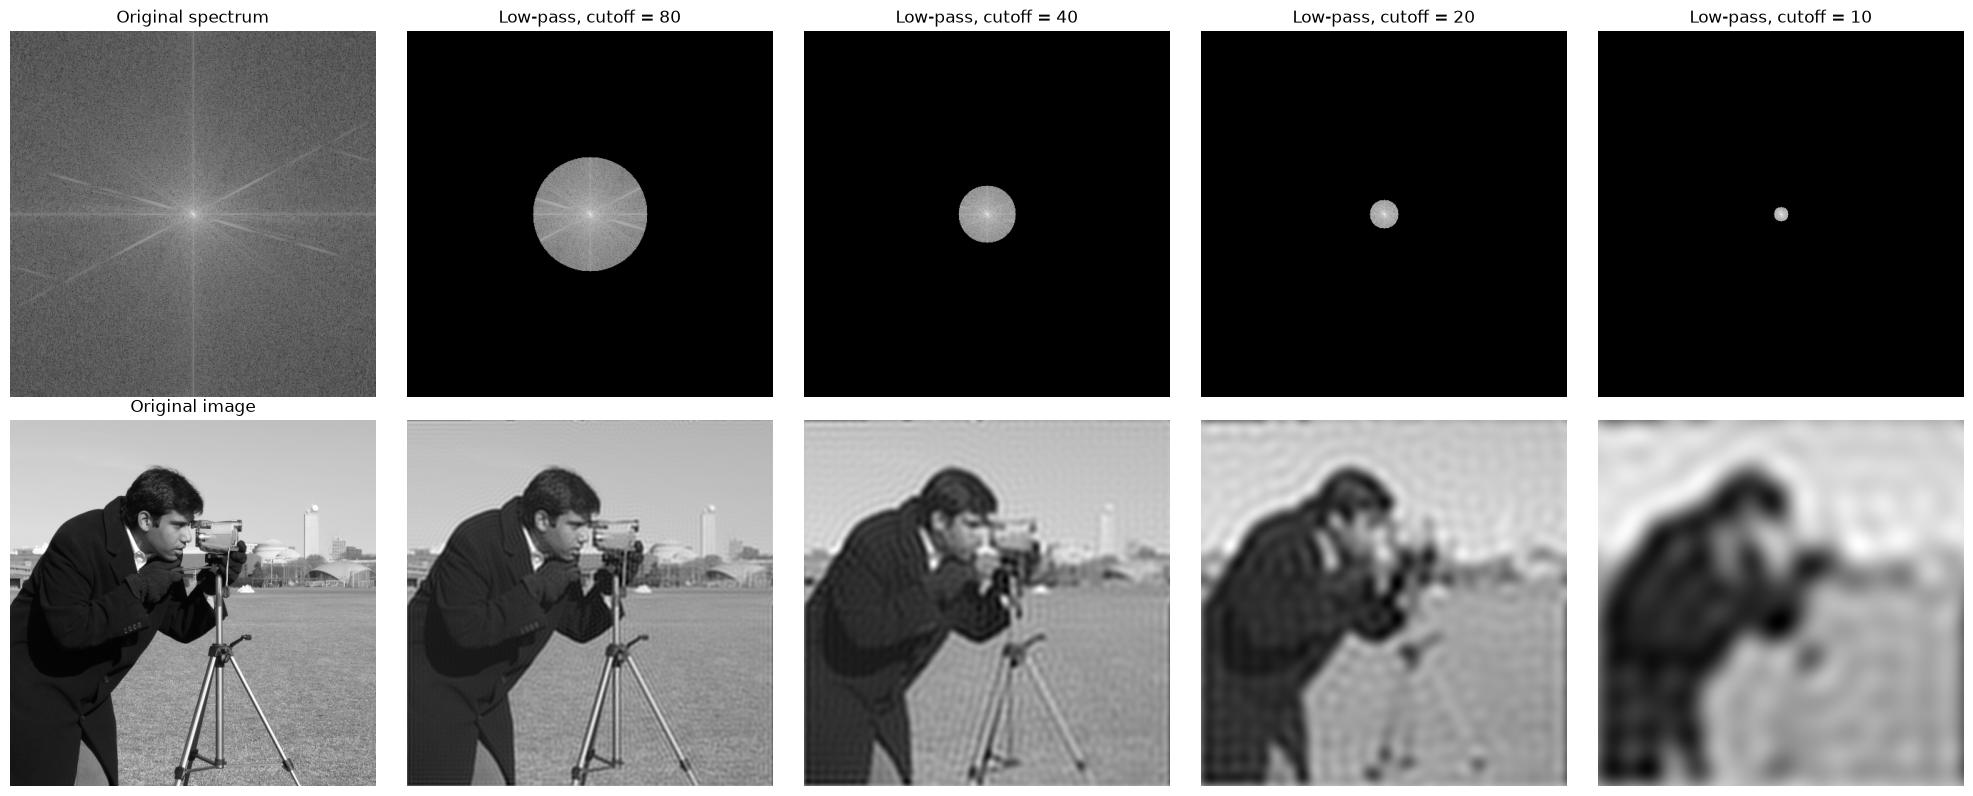

In [14]:
# Ideal low-pass filter. The mask keeps every frequency whose distance from the
# origin is at most the cutoff frequency. A larger cutoff keeps more
# frequencies, so more detail survives; a smaller cutoff blurs further.
H, W = image.shape
u = np.arange(W) - W // 2
v = np.arange(H) - H // 2
uu, vv = np.meshgrid(u, v)
distance = np.sqrt(uu**2 + vv**2)

# Descending, so the blurring increases as the panels move away from the original.
cutoff_frequencies = [80, 40, 20, 10]

fig, axes = plt.subplots(2, len(cutoff_frequencies) + 1, figsize=(4 * (len(cutoff_frequencies) + 1), 8))

axes[0, 0].imshow(magnitude_log, cmap="gray")
axes[0, 0].set_title("Original spectrum")
axes[0, 0].axis("off")
axes[1, 0].imshow(image, cmap="gray")
axes[1, 0].set_title("Original image")
axes[1, 0].axis("off")

for col, cutoff in enumerate(cutoff_frequencies, start=1):
    mask = distance <= cutoff
    result = np.real(np.fft.ifft2(np.fft.ifftshift(F * mask)))

    axes[0, col].imshow(np.log(1 + np.abs(F * mask)), cmap="gray")
    axes[0, col].set_title(f"Low-pass, cutoff = {cutoff}")
    axes[0, col].axis("off")

    axes[1, col].imshow(result, cmap="gray")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()


## 1.3 — High-pass filter


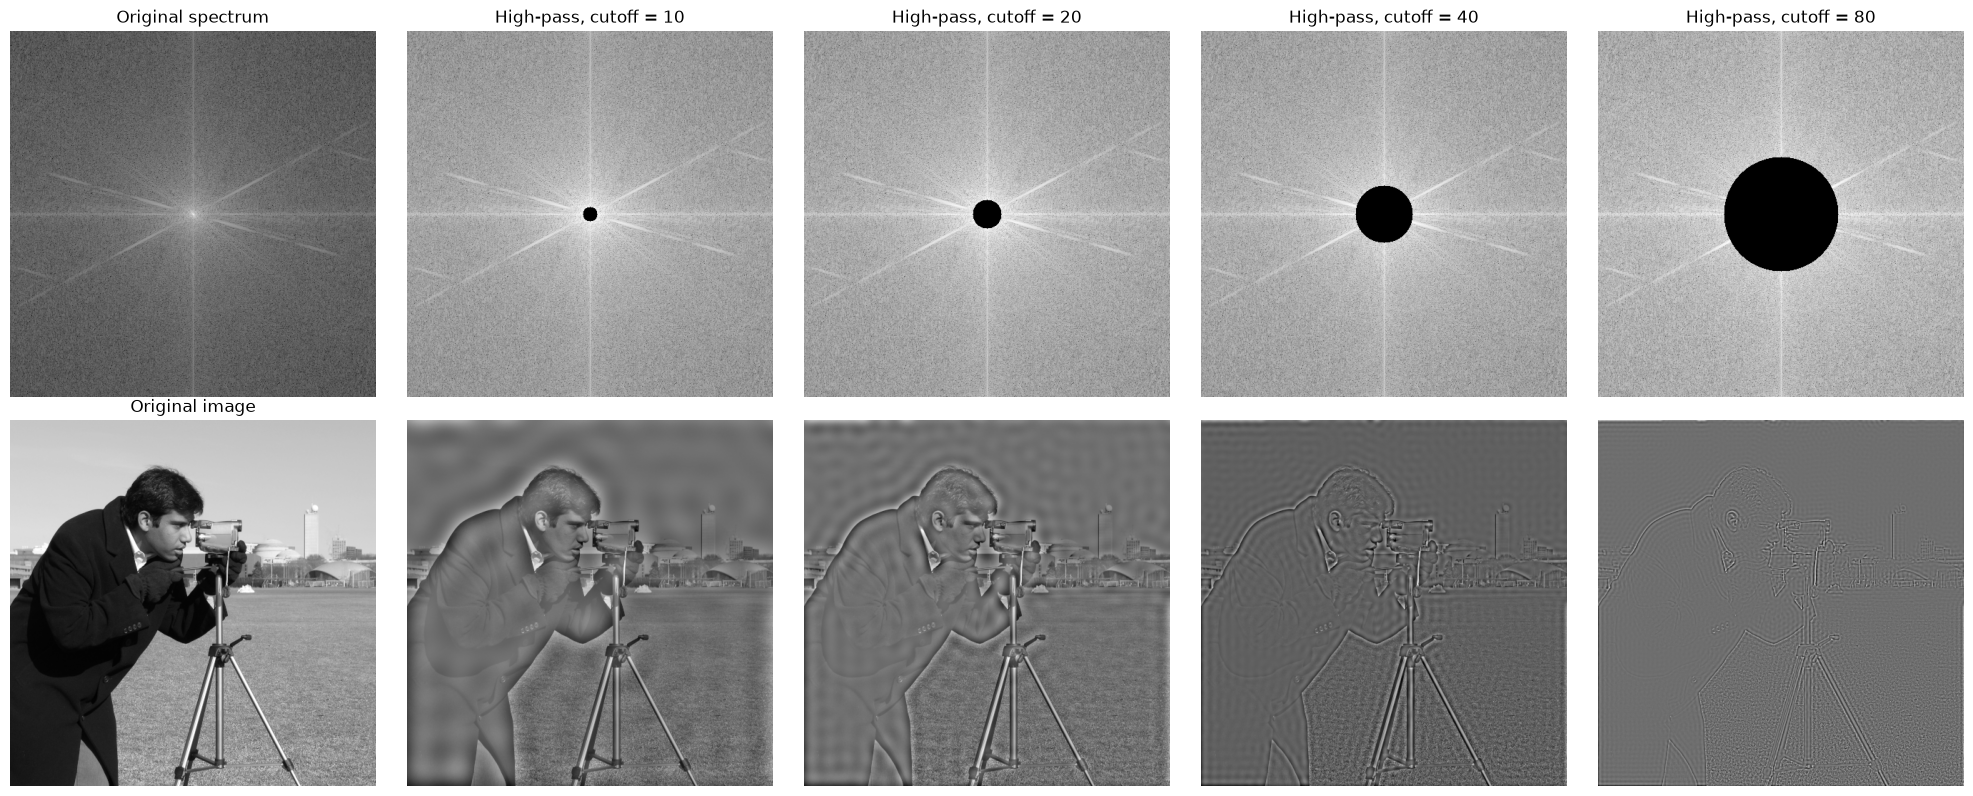

In [15]:
# Ideal high-pass filter: the complement of the low-pass mask. Frequencies
# closer to the origin than the cutoff are removed, so only the high
# frequencies that carry edges and fine detail remain.
# Ascending, so the panels start closest to the original and become
# progressively more edge-only.
cutoff_frequencies = [10, 20, 40, 80]

fig, axes = plt.subplots(2, len(cutoff_frequencies) + 1, figsize=(4 * (len(cutoff_frequencies) + 1), 8))

axes[0, 0].imshow(magnitude_log, cmap="gray")
axes[0, 0].set_title("Original spectrum")
axes[0, 0].axis("off")
axes[1, 0].imshow(image, cmap="gray")
axes[1, 0].set_title("Original image")
axes[1, 0].axis("off")

for col, cutoff in enumerate(cutoff_frequencies, start=1):
    mask = distance > cutoff
    result = np.real(np.fft.ifft2(np.fft.ifftshift(F * mask)))

    axes[0, col].imshow(np.log(1 + np.abs(F * mask)), cmap="gray")
    axes[0, col].set_title(f"High-pass, cutoff = {cutoff}")
    axes[0, col].axis("off")

    axes[1, col].imshow(result, cmap="gray")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()


## 1.4 — Compression by keeping a percentage of coefficients


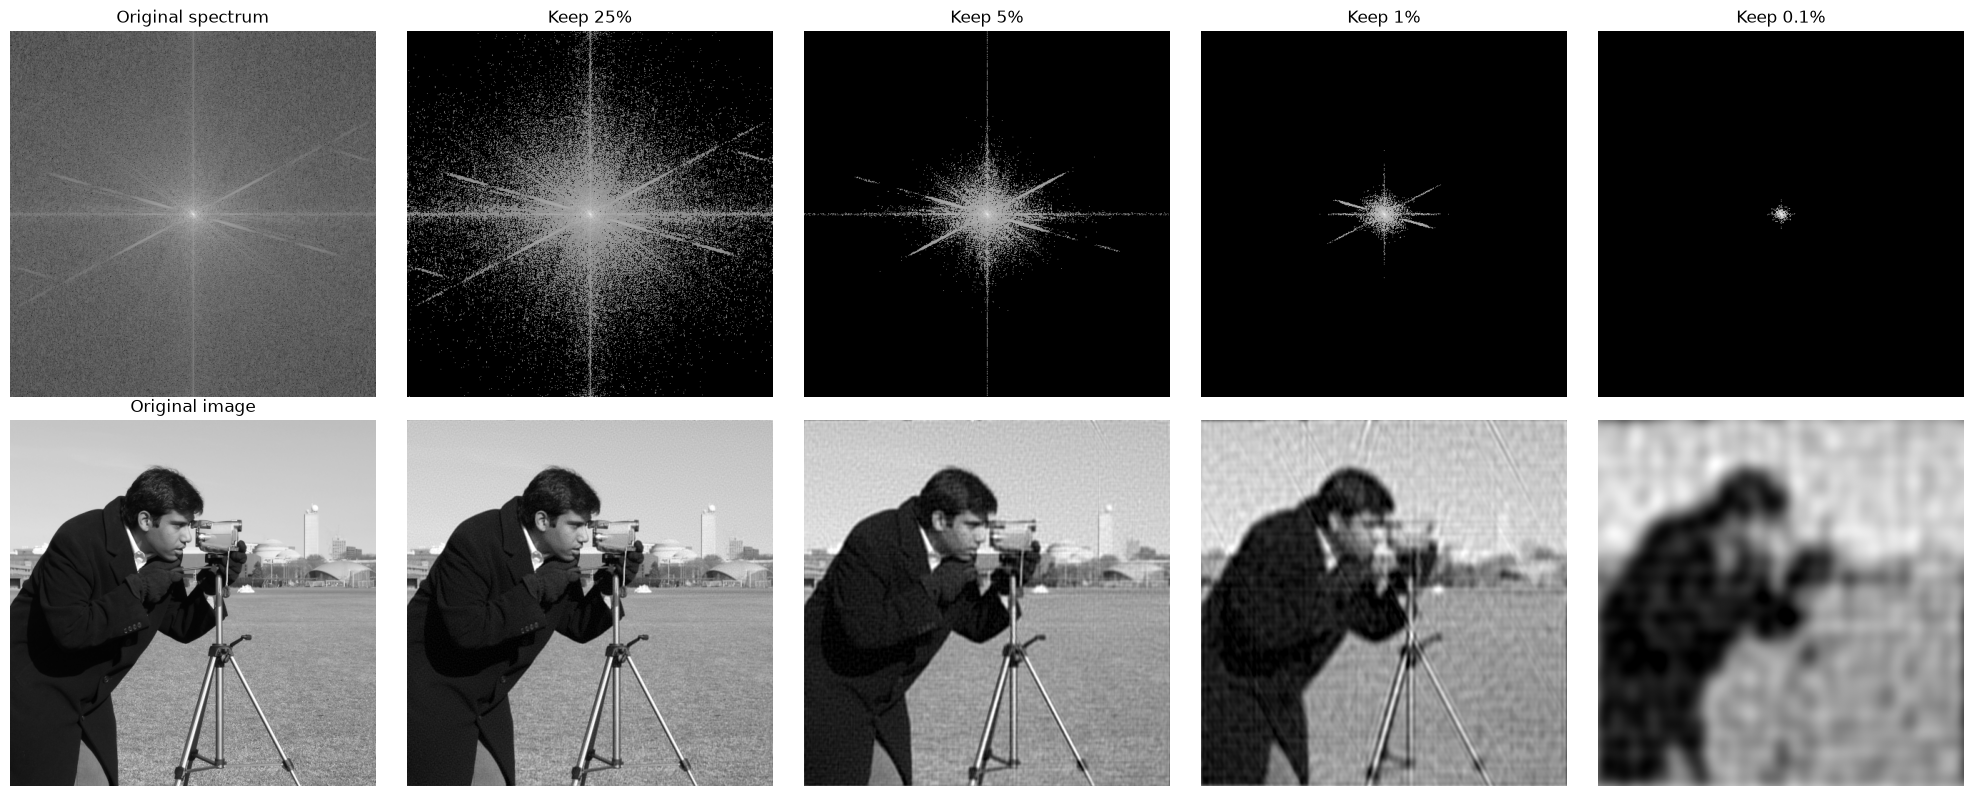

In [16]:
# Compression: keep only the largest-magnitude Fourier coefficients, since the
# image energy is concentrated in a few of them. The rest are set to zero.
# The steps drop quickly and end low, so the degradation is easy to see.
keep_percentages = [25, 5, 1, 0.1]

magnitudes = np.abs(F)
sorted_magnitudes = np.sort(magnitudes.ravel())

fig, axes = plt.subplots(2, len(keep_percentages) + 1, figsize=(4 * (len(keep_percentages) + 1), 8))

axes[0, 0].imshow(magnitude_log, cmap="gray")
axes[0, 0].set_title("Original spectrum")
axes[0, 0].axis("off")
axes[1, 0].imshow(image, cmap="gray")
axes[1, 0].set_title("Original image")
axes[1, 0].axis("off")

for col, percentage in enumerate(keep_percentages, start=1):
    # Threshold: the magnitude below which coefficients are discarded.
    threshold = sorted_magnitudes[int((1 - percentage / 100) * sorted_magnitudes.size)]
    mask = magnitudes >= threshold

    compressed = np.real(np.fft.ifft2(np.fft.ifftshift(F * mask)))
    compressed = np.clip(compressed, 0, 255)

    axes[0, col].imshow(np.log(1 + np.abs(F * mask)), cmap="gray")
    axes[0, col].set_title(f"Keep {percentage}%")
    axes[0, col].axis("off")

    axes[1, col].imshow(compressed, cmap="gray")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()


### Quality metrics and compression ratio

  Keep %  Coefficients        MSE     RMSE  PSNR (dB)  Compression
      25        65,536       32.5     5.70      33.02         4.0:1
       5        13,107      109.2    10.45      27.75        20.0:1
       1         2,621      265.2    16.28      23.90       100.0:1
     0.1           262      653.4    25.56      19.98      1000.0:1


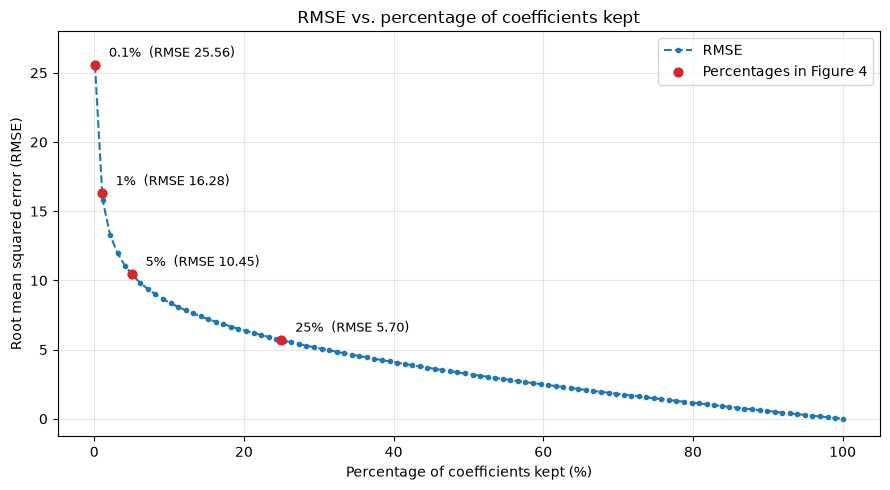

Min RMSE: 0.00 (at 100.0% kept)
Max RMSE: 25.56 (at 0.1% kept)


In [17]:
def reconstruct(image, F, magnitudes, sorted_magnitudes, percentage):
    """Reconstruct the image keeping the largest `percentage` of coefficients."""
    threshold = sorted_magnitudes[int((1 - percentage / 100) * sorted_magnitudes.size)]
    mask = magnitudes >= threshold
    result = np.real(np.fft.ifft2(np.fft.ifftshift(F * mask)))
    return np.clip(result, 0, 255)


def mse(a, b):
    return np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)


def rmse(a, b):
    return np.sqrt(mse(a, b))


def psnr(a, b):
    error = mse(a, b)
    return 10 * np.log10(255**2 / error) if error > 0 else float("inf")


print(f"{'Keep %':>8} {'Coefficients':>13} {'MSE':>10} {'RMSE':>8} {'PSNR (dB)':>10} {'Compression':>12}")
for percentage in keep_percentages:
    result = reconstruct(image, F, magnitudes, sorted_magnitudes, percentage)
    kept = int(percentage / 100 * magnitudes.size)
    print(f"{percentage:>8} {kept:>13,} {mse(image, result):>10.1f} "
          f"{rmse(image, result):>8.2f} {psnr(image, result):>10.2f} {100 / percentage:>11.1f}:1")

# Dense sweep for the curve. The percentage is on a linear 0-100 axis so the
# whole range is easy to read.
sweep = np.linspace(0.1, 100, 100)
rmse_values = [rmse(image, reconstruct(image, F, magnitudes, sorted_magnitudes, p)) for p in sweep]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sweep, rmse_values, marker="o", markersize=3, linestyle="--", label="RMSE")
ax.set_title("RMSE vs. percentage of coefficients kept")
ax.set_xlabel("Percentage of coefficients kept (%)")
ax.set_ylabel("Root mean squared error (RMSE)")
ax.set_ylim(top=28)
ax.grid(True, alpha=0.3)

# Mark the percentages from Figure 4 as points rather than vertical lines,
# since 0.1% and 1% are too close together on a linear axis to tell apart.
table_rmse = [rmse(image, reconstruct(image, F, magnitudes, sorted_magnitudes, p)) for p in keep_percentages]
ax.scatter(keep_percentages, table_rmse, color="tab:red", s=40, zorder=3, label="Percentages in Figure 4")
for percentage, value in zip(keep_percentages, table_rmse):
    ax.annotate(f"{percentage}%  (RMSE {value:.2f})", xy=(percentage, value), xytext=(10, 6),
                textcoords="offset points", fontsize=9)
ax.legend()

plt.tight_layout()
plt.show()

print(f"Min RMSE: {min(rmse_values):.2f} (at {sweep[int(np.argmin(rmse_values))]:.1f}% kept)")
print(f"Max RMSE: {max(rmse_values):.2f} (at {sweep[int(np.argmax(rmse_values))]:.1f}% kept)")
